In [1]:
import pandas as pd
import numpy as np
from lightgbm import LGBMRegressor, early_stopping
import optuna
import sys
from pathlib import Path
import warnings
import torch

DIR_ROOT = Path.cwd().parent.parent.parent
sys.path.insert(0, str(DIR_ROOT))

warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2

/home/koyo-ai/miniconda3/envs/homeless/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SEED = 987
TRACK = "off_market"                     # "off_market" or "list_aware"
VAL_START = pd.Timestamp("2025-12-01")    # sales on or after this date are validation
N_TRIALS = 20                             # optuna trials
N_ESTIMATORS = 1000                      # NOT USED
EARLY_STOPPING_ROUNDS = 100                 # NOT USED
ES_FRACTION = 0.0                         # latest share of each fold's training rows used for early stopping
K_FOLDS = 5                              # CV validates on each of the last K_FOLDS months before VAL_START
FS_MONTHS = 3                            # feature selection scores on each of the last FS_MONTHS months before VAL_START
DEBUG = True                             # print MdAPE and MAPE for every fold

In [3]:
import data

listings = data.load("listings")
off_market = data.load("off_market")
list_aware = data.load("list_aware")

In [4]:
from xxbonkxx_features import off_market_features, list_aware_features

make_features = off_market_features if TRACK == "off_market" else list_aware_features

train = listings[listings["date_sold"] < VAL_START]
val = listings[listings["date_sold"] >= VAL_START]

y_train = np.log(train["sold_price"])
y_val = np.log(val["sold_price"])

# Column names only. The matrices are built inside each fold, then again on train and val after tuning.
print(f"Features: {make_features(train.iloc[:10]).columns.tolist()}")
print(f"train: {len(train):,} sales up to {VAL_START.date()}")
print(f"val:   {len(val):,} sales from {VAL_START.date()}")

Features: ['square_feet', 'bedrooms', 'washrooms', 'parking', 'lot_front', 'lot_depth', 'latitude', 'longitude', 'community', 'house_type', 'house_style', 'month', 'year', 'day', 'is_apartment', 'is_apartment_x_square_feet_0', 'is_apartment_x_square_feet_1', 'is_apartment_x_bedrooms_0', 'is_apartment_x_bedrooms_1', 'is_apartment_x_washrooms_0', 'is_apartment_x_washrooms_1', 'is_apartment_x_parking_0', 'is_apartment_x_parking_1', 'square_feet_x_bedrooms', 'square_feet_x_washrooms', 'square_feet_x_parking', 'bedrooms_x_washrooms', 'bedrooms_x_parking', 'washrooms_x_parking', 'month_sin', 'month_cos', 'lag_annual', 'lag_semi_annual', 'community_median', 'community_median_lag_6m', 'community_median_lag_1y', 'community_change_6m', 'community_change_1y', 'community_to_market', 'remarks_renovated', 'remarks_updated', 'remarks_turnkey', 'remarks_kitchen', 'remarks_premium_kitchen', 'remarks_wood_floor', 'remarks_clean', 'remarks_needs_work', 'remarks_dated', 'remarks_split_bedroom', 'remarks_o

In [5]:
def mdape_log(y_log, pred_log):
    return 100 * np.median(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))

def mape_log(y_log, pred_log):
    return 100 * np.mean(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))

def mdape(y, pred):
    return 100 * np.median(np.abs(pred - y) / np.abs(y))

def mape(y, pred):
    return 100 * np.mean(np.abs(pred - y) / np.abs(y))

target_space = "log"

In [6]:
from training_utils import walk_forward_folds

CATEGORICAL_FEATURES = [
        "community",
        "house_style",
        "house_type",
    ]

def align_categories(X_tr, X_va):
    """Give X_va's categorical columns the categories of X_tr. Unseen values become missing."""
    X_va = X_va.copy()
    for col in X_tr.select_dtypes("category"):
        X_va[col] = X_va[col].cat.set_categories(X_tr[col].cat.categories)
    return X_va


def cv_months(K, end=VAL_START):
    """The K calendar months just before `end`, oldest first."""
    return pd.period_range(end=(end - pd.Timedelta(days=1)).to_period("M"), periods=K, freq="M")


def cross_val(folds, y, params, debug=False, target_space="log"):
    """Monthly walk-forward CV, the way `python run.py validate` works: each fold
    predicts one month's sales (answers hidden) with a model trained on every earlier sale.
    `folds` comes from walk_forward_folds, so features are built once, not per trial.
    `y` is indexed like the homes the folds were built from. Early stopping uses the
    latest ES_FRACTION of each fold's training rows, never the validated month.
    Returns (mean validation loss, mean boosting rounds used) over the folds."""
    mdape_scores = []
    mape_scores = []
    rounds = []
    for fold in folds:
        X_tr, X_va = fold.X_train, fold.X_homes
        n_fit = int(len(X_tr) * (1 - ES_FRACTION))
        X_fit, X_es = X_tr.iloc[:n_fit], X_tr.iloc[n_fit:]
        y_fit, y_es, y_va = y.loc[X_fit.index], y.loc[X_es.index], y.loc[X_va.index]

        model = LGBMRegressor(**params, random_state=SEED, verbosity=-1)
        model.fit(X_fit, y_fit, categorical_feature=CATEGORICAL_FEATURES)
        rounds.append(model.best_iteration_)
        pred = model.predict(X_va)
        if target_space == "log":
            mdape_scores.append(mdape_log(y_va, pred))
        else:
            mdape_scores.append(mdape(y_va, pred))

        if target_space == "log":
            mape_scores.append(mape_log(y_va, pred))
        else:
            mape_scores.append(mape(y_va, pred))

        if debug:
            mdape_error = mdape_scores[-1]
            mape_error = mape_scores[-1]
            print(f"{fold.month}: train {len(X_fit):,}  early stop {len(X_es):,}  val {len(X_va):,}  "
                  f"rounds {rounds[-1]}  MdAPE {mdape_error:.2f}%  MAPE {mape_error:.2f}%", flush=True)

    print(f"mean MdAPE {np.mean(mdape_scores):.2f}%  mean MAPE {np.mean(mape_scores):.2f}%", flush=True)
    return np.mean(mdape_scores), int(np.mean(rounds))

In [7]:
# Built once and shared by every trial: the last K_FOLDS months before VAL_START.
cv_folds = walk_forward_folds(train, make_features, TRACK, months=cv_months(K_FOLDS))
print("CV months:", ", ".join(str(fold.month) for fold in cv_folds))

def objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, step=0.01),
        "num_leaves": trial.suggest_int("num_leaves", 15, 255),
        "max_depth": trial.suggest_int("max_depth", 3, 13),
        "n_estimators": trial.suggest_int("n_estimators", 200, 2000, step=200),
        "subsample_freq": 1,  # LightGBM ignores subsample unless bagging runs every k rounds
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.1, 1.0, step=0.1),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
        "min_split_gain": trial.suggest_float("min_split_gain", 0, 0.1, step=0.01),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "feature_fraction": trial.suggest_float("feature_fraction", 0.1, 1.0, step=0.1),
        "metric": "mae",
        "device":"gpu"
    }
    score, n_rounds = cross_val(cv_folds, y_train, params, debug=DEBUG, target_space=target_space)
    trial.set_user_attr("n_rounds", n_rounds)
    return score

CV months: 2025-07, 2025-08, 2025-09, 2025-10, 2025-11


In [8]:
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED), study_name="VAPE GOD VAPE GOD VAPE GOD 420 420 696969!!!!")
study.optimize(objective, n_trials=N_TRIALS)

print("best CV MdAPE:", round(study.best_value, 2))
print("best params:", study.best_params)
print("boosting rounds:", study.best_trial.user_attrs["n_rounds"])

[I 2026-10-28 09:49:29,024] A new study created in memory with name: VAPE GOD VAPE GOD VAPE GOD 420 420 696969!!!!


2025-07: train 130,045  early stop 0  val 2,068  rounds 0  MdAPE 9.78%  MAPE 12.79%
2025-08: train 132,113  early stop 0  val 1,666  rounds 0  MdAPE 9.62%  MAPE 12.29%
2025-09: train 133,779  early stop 0  val 2,035  rounds 0  MdAPE 9.37%  MAPE 12.09%
2025-10: train 135,814  early stop 0  val 2,250  rounds 0  MdAPE 9.54%  MAPE 11.73%
2025-11: train 138,064  early stop 0  val 1,867  rounds 0  MdAPE 9.66%  MAPE 12.39%
mean MdAPE 9.59%  mean MAPE 12.26%


[I 2026-10-28 09:50:04,278] Trial 0 finished with value: 9.594904397933416 and parameters: {'learning_rate': 0.05, 'num_leaves': 109, 'max_depth': 12, 'n_estimators': 1000, 'colsample_bytree': 0.9, 'min_child_samples': 93, 'min_split_gain': 0.1, 'reg_lambda': 7.103714746188992, 'reg_alpha': 0.0013187949354214168, 'feature_fraction': 0.1}. Best is trial 0 with value: 9.594904397933416.


2025-07: train 130,045  early stop 0  val 2,068  rounds 0  MdAPE 9.82%  MAPE 12.85%
2025-08: train 132,113  early stop 0  val 1,666  rounds 0  MdAPE 9.61%  MAPE 12.20%
2025-09: train 133,779  early stop 0  val 2,035  rounds 0  MdAPE 9.62%  MAPE 12.06%
2025-10: train 135,814  early stop 0  val 2,250  rounds 0  MdAPE 8.79%  MAPE 11.50%
2025-11: train 138,064  early stop 0  val 1,867  rounds 0  MdAPE 9.41%  MAPE 12.03%
mean MdAPE 9.45%  mean MAPE 12.13%


[I 2026-10-28 09:50:18,977] Trial 1 finished with value: 9.450881399020062 and parameters: {'learning_rate': 0.09, 'num_leaves': 31, 'max_depth': 11, 'n_estimators': 1600, 'colsample_bytree': 0.4, 'min_child_samples': 29, 'min_split_gain': 0.08, 'reg_lambda': 4.791227993546376, 'reg_alpha': 0.0058203973119644765, 'feature_fraction': 0.9}. Best is trial 1 with value: 9.450881399020062.


2025-07: train 130,045  early stop 0  val 2,068  rounds 0  MdAPE 9.08%  MAPE 12.35%
2025-08: train 132,113  early stop 0  val 1,666  rounds 0  MdAPE 9.24%  MAPE 11.77%
2025-09: train 133,779  early stop 0  val 2,035  rounds 0  MdAPE 9.26%  MAPE 11.81%
2025-10: train 135,814  early stop 0  val 2,250  rounds 0  MdAPE 9.01%  MAPE 11.28%
2025-11: train 138,064  early stop 0  val 1,867  rounds 0  MdAPE 8.94%  MAPE 11.83%
mean MdAPE 9.11%  mean MAPE 11.81%


[I 2026-10-28 09:50:57,403] Trial 2 finished with value: 9.107533177317725 and parameters: {'learning_rate': 0.05, 'num_leaves': 199, 'max_depth': 9, 'n_estimators': 1400, 'colsample_bytree': 1.0, 'min_child_samples': 82, 'min_split_gain': 0.03, 'reg_lambda': 0.013397845804991282, 'reg_alpha': 4.998638172864346, 'feature_fraction': 0.5}. Best is trial 2 with value: 9.107533177317725.


2025-07: train 130,045  early stop 0  val 2,068  rounds 0  MdAPE 9.89%  MAPE 12.94%
2025-08: train 132,113  early stop 0  val 1,666  rounds 0  MdAPE 9.77%  MAPE 12.35%
2025-09: train 133,779  early stop 0  val 2,035  rounds 0  MdAPE 9.56%  MAPE 12.23%
2025-10: train 135,814  early stop 0  val 2,250  rounds 0  MdAPE 9.39%  MAPE 11.90%
2025-11: train 138,064  early stop 0  val 1,867  rounds 0  MdAPE 9.48%  MAPE 12.42%
mean MdAPE 9.62%  mean MAPE 12.37%


[I 2026-10-28 09:51:05,871] Trial 3 finished with value: 9.616995010805796 and parameters: {'learning_rate': 0.09999999999999999, 'num_leaves': 103, 'max_depth': 6, 'n_estimators': 200, 'colsample_bytree': 0.6, 'min_child_samples': 58, 'min_split_gain': 0.05, 'reg_lambda': 0.007810199652857199, 'reg_alpha': 0.06821146368694334, 'feature_fraction': 0.30000000000000004}. Best is trial 2 with value: 9.107533177317725.


2025-07: train 130,045  early stop 0  val 2,068  rounds 0  MdAPE 9.48%  MAPE 12.43%
2025-08: train 132,113  early stop 0  val 1,666  rounds 0  MdAPE 9.47%  MAPE 11.90%
2025-09: train 133,779  early stop 0  val 2,035  rounds 0  MdAPE 8.96%  MAPE 11.77%
2025-10: train 135,814  early stop 0  val 2,250  rounds 0  MdAPE 9.04%  MAPE 11.38%
2025-11: train 138,064  early stop 0  val 1,867  rounds 0  MdAPE 9.34%  MAPE 12.07%
mean MdAPE 9.26%  mean MAPE 11.91%


[I 2026-10-28 09:52:43,357] Trial 4 finished with value: 9.259542248761868 and parameters: {'learning_rate': 0.03, 'num_leaves': 170, 'max_depth': 11, 'n_estimators': 1800, 'colsample_bytree': 0.9, 'min_child_samples': 39, 'min_split_gain': 0.08, 'reg_lambda': 0.6719572464324033, 'reg_alpha': 0.012513269016993844, 'feature_fraction': 0.2}. Best is trial 2 with value: 9.107533177317725.


2025-07: train 130,045  early stop 0  val 2,068  rounds 0  MdAPE 8.77%  MAPE 11.59%
2025-08: train 132,113  early stop 0  val 1,666  rounds 0  MdAPE 8.40%  MAPE 11.12%
2025-09: train 133,779  early stop 0  val 2,035  rounds 0  MdAPE 8.78%  MAPE 11.10%
2025-10: train 135,814  early stop 0  val 2,250  rounds 0  MdAPE 8.41%  MAPE 10.77%
2025-11: train 138,064  early stop 0  val 1,867  rounds 0  MdAPE 8.59%  MAPE 11.38%
mean MdAPE 8.59%  mean MAPE 11.19%


[I 2026-10-28 09:55:14,054] Trial 5 finished with value: 8.589284160341814 and parameters: {'learning_rate': 0.08, 'num_leaves': 139, 'max_depth': 10, 'n_estimators': 800, 'colsample_bytree': 0.8, 'min_child_samples': 65, 'min_split_gain': 0.0, 'reg_lambda': 0.022743159590986432, 'reg_alpha': 0.007278500154594164, 'feature_fraction': 0.2}. Best is trial 5 with value: 8.589284160341814.


2025-07: train 130,045  early stop 0  val 2,068  rounds 0  MdAPE 9.43%  MAPE 12.70%
2025-08: train 132,113  early stop 0  val 1,666  rounds 0  MdAPE 9.42%  MAPE 12.12%
2025-09: train 133,779  early stop 0  val 2,035  rounds 0  MdAPE 9.59%  MAPE 11.96%
2025-10: train 135,814  early stop 0  val 2,250  rounds 0  MdAPE 8.99%  MAPE 11.43%
2025-11: train 138,064  early stop 0  val 1,867  rounds 0  MdAPE 8.92%  MAPE 11.87%
mean MdAPE 9.27%  mean MAPE 12.02%


[I 2026-10-28 09:55:27,129] Trial 6 finished with value: 9.270417836610687 and parameters: {'learning_rate': 0.09, 'num_leaves': 100, 'max_depth': 4, 'n_estimators': 1800, 'colsample_bytree': 0.30000000000000004, 'min_child_samples': 74, 'min_split_gain': 0.04, 'reg_lambda': 0.2690013698362912, 'reg_alpha': 0.002273875199313815, 'feature_fraction': 0.9}. Best is trial 5 with value: 8.589284160341814.


2025-07: train 130,045  early stop 0  val 2,068  rounds 0  MdAPE 9.94%  MAPE 12.81%
2025-08: train 132,113  early stop 0  val 1,666  rounds 0  MdAPE 9.78%  MAPE 12.34%
2025-09: train 133,779  early stop 0  val 2,035  rounds 0  MdAPE 9.25%  MAPE 12.10%
2025-10: train 135,814  early stop 0  val 2,250  rounds 0  MdAPE 9.46%  MAPE 11.89%
2025-11: train 138,064  early stop 0  val 1,867  rounds 0  MdAPE 9.77%  MAPE 12.55%
mean MdAPE 9.64%  mean MAPE 12.34%


[I 2026-10-28 09:55:42,802] Trial 7 finished with value: 9.639138173097631 and parameters: {'learning_rate': 0.060000000000000005, 'num_leaves': 15, 'max_depth': 12, 'n_estimators': 600, 'colsample_bytree': 0.6, 'min_child_samples': 69, 'min_split_gain': 0.09, 'reg_lambda': 2.519861225561361, 'reg_alpha': 0.2966894233087178, 'feature_fraction': 0.30000000000000004}. Best is trial 5 with value: 8.589284160341814.


2025-07: train 130,045  early stop 0  val 2,068  rounds 0  MdAPE 9.40%  MAPE 12.37%
2025-08: train 132,113  early stop 0  val 1,666  rounds 0  MdAPE 9.23%  MAPE 11.81%
2025-09: train 133,779  early stop 0  val 2,035  rounds 0  MdAPE 9.10%  MAPE 11.62%
2025-10: train 135,814  early stop 0  val 2,250  rounds 0  MdAPE 8.78%  MAPE 11.19%
2025-11: train 138,064  early stop 0  val 1,867  rounds 0  MdAPE 8.94%  MAPE 11.78%
mean MdAPE 9.09%  mean MAPE 11.75%


[I 2026-10-28 09:57:05,896] Trial 8 finished with value: 9.088177407545496 and parameters: {'learning_rate': 0.02, 'num_leaves': 119, 'max_depth': 6, 'n_estimators': 1600, 'colsample_bytree': 0.1, 'min_child_samples': 5, 'min_split_gain': 0.01, 'reg_lambda': 9.311413198108736, 'reg_alpha': 0.030559905399179667, 'feature_fraction': 0.8}. Best is trial 5 with value: 8.589284160341814.


2025-07: train 130,045  early stop 0  val 2,068  rounds 0  MdAPE 9.58%  MAPE 12.50%
2025-08: train 132,113  early stop 0  val 1,666  rounds 0  MdAPE 9.50%  MAPE 11.89%
2025-09: train 133,779  early stop 0  val 2,035  rounds 0  MdAPE 9.26%  MAPE 11.85%
2025-10: train 135,814  early stop 0  val 2,250  rounds 0  MdAPE 9.04%  MAPE 11.56%
2025-11: train 138,064  early stop 0  val 1,867  rounds 0  MdAPE 9.25%  MAPE 12.11%
mean MdAPE 9.32%  mean MAPE 11.98%


[I 2026-10-28 09:57:28,542] Trial 9 finished with value: 9.324758388045595 and parameters: {'learning_rate': 0.09999999999999999, 'num_leaves': 124, 'max_depth': 13, 'n_estimators': 1200, 'colsample_bytree': 0.6, 'min_child_samples': 40, 'min_split_gain': 0.09, 'reg_lambda': 2.1227964272241358, 'reg_alpha': 0.11463214978336936, 'feature_fraction': 0.6}. Best is trial 5 with value: 8.589284160341814.


2025-07: train 130,045  early stop 0  val 2,068  rounds 0  MdAPE 8.60%  MAPE 11.47%
2025-08: train 132,113  early stop 0  val 1,666  rounds 0  MdAPE 8.03%  MAPE 10.88%
2025-09: train 133,779  early stop 0  val 2,035  rounds 0  MdAPE 8.30%  MAPE 10.97%
2025-10: train 135,814  early stop 0  val 2,250  rounds 0  MdAPE 8.42%  MAPE 10.60%
2025-11: train 138,064  early stop 0  val 1,867  rounds 0  MdAPE 8.15%  MAPE 11.11%
mean MdAPE 8.30%  mean MAPE 11.01%


[I 2026-10-28 09:58:46,388] Trial 10 finished with value: 8.299956582354913 and parameters: {'learning_rate': 0.09, 'num_leaves': 217, 'max_depth': 12, 'n_estimators': 1000, 'colsample_bytree': 1.0, 'min_child_samples': 39, 'min_split_gain': 0.01, 'reg_lambda': 0.008664328052165472, 'reg_alpha': 0.024896236941145386, 'feature_fraction': 0.30000000000000004}. Best is trial 10 with value: 8.299956582354913.


2025-07: train 130,045  early stop 0  val 2,068  rounds 0  MdAPE 9.39%  MAPE 12.22%
2025-08: train 132,113  early stop 0  val 1,666  rounds 0  MdAPE 8.89%  MAPE 11.66%
2025-09: train 133,779  early stop 0  val 2,035  rounds 0  MdAPE 9.15%  MAPE 11.70%
2025-10: train 135,814  early stop 0  val 2,250  rounds 0  MdAPE 9.01%  MAPE 11.33%
2025-11: train 138,064  early stop 0  val 1,867  rounds 0  MdAPE 9.21%  MAPE 12.07%
mean MdAPE 9.13%  mean MAPE 11.80%


[I 2026-10-28 09:59:44,492] Trial 11 finished with value: 9.127479011022858 and parameters: {'learning_rate': 0.09, 'num_leaves': 123, 'max_depth': 11, 'n_estimators': 1000, 'colsample_bytree': 1.0, 'min_child_samples': 39, 'min_split_gain': 0.02, 'reg_lambda': 0.07882159177697577, 'reg_alpha': 0.012264977964437918, 'feature_fraction': 0.1}. Best is trial 10 with value: 8.299956582354913.


2025-07: train 130,045  early stop 0  val 2,068  rounds 0  MdAPE 8.28%  MAPE 11.31%
2025-08: train 132,113  early stop 0  val 1,666  rounds 0  MdAPE 7.99%  MAPE 10.69%
2025-09: train 133,779  early stop 0  val 2,035  rounds 0  MdAPE 8.27%  MAPE 10.65%
2025-10: train 135,814  early stop 0  val 2,250  rounds 0  MdAPE 8.04%  MAPE 10.33%
2025-11: train 138,064  early stop 0  val 1,867  rounds 0  MdAPE 8.09%  MAPE 10.91%
mean MdAPE 8.13%  mean MAPE 10.78%


[I 2026-10-28 10:02:02,259] Trial 12 finished with value: 8.133695152247954 and parameters: {'learning_rate': 0.06999999999999999, 'num_leaves': 177, 'max_depth': 13, 'n_estimators': 800, 'colsample_bytree': 0.9, 'min_child_samples': 49, 'min_split_gain': 0.0, 'reg_lambda': 0.001983410276644759, 'reg_alpha': 0.0030328786150909254, 'feature_fraction': 0.30000000000000004}. Best is trial 12 with value: 8.133695152247954.


2025-07: train 130,045  early stop 0  val 2,068  rounds 0  MdAPE 8.39%  MAPE 11.42%
2025-08: train 132,113  early stop 0  val 1,666  rounds 0  MdAPE 8.14%  MAPE 10.76%
2025-09: train 133,779  early stop 0  val 2,035  rounds 0  MdAPE 8.28%  MAPE 10.78%
2025-10: train 135,814  early stop 0  val 2,250  rounds 0  MdAPE 8.22%  MAPE 10.44%
2025-11: train 138,064  early stop 0  val 1,867  rounds 0  MdAPE 8.42%  MAPE 11.17%
mean MdAPE 8.29%  mean MAPE 10.91%


[I 2026-10-28 10:03:56,298] Trial 13 finished with value: 8.288333098565534 and parameters: {'learning_rate': 0.05, 'num_leaves': 185, 'max_depth': 13, 'n_estimators': 800, 'colsample_bytree': 0.8, 'min_child_samples': 37, 'min_split_gain': 0.01, 'reg_lambda': 0.0024430923881151073, 'reg_alpha': 0.003213567737241144, 'feature_fraction': 0.4}. Best is trial 12 with value: 8.133695152247954.


2025-07: train 130,045  early stop 0  val 2,068  rounds 0  MdAPE 8.43%  MAPE 11.34%
2025-08: train 132,113  early stop 0  val 1,666  rounds 0  MdAPE 8.11%  MAPE 10.79%
2025-09: train 133,779  early stop 0  val 2,035  rounds 0  MdAPE 8.31%  MAPE 10.79%
2025-10: train 135,814  early stop 0  val 2,250  rounds 0  MdAPE 8.08%  MAPE 10.39%
2025-11: train 138,064  early stop 0  val 1,867  rounds 0  MdAPE 8.20%  MAPE 10.99%
mean MdAPE 8.23%  mean MAPE 10.86%


[I 2026-10-28 10:07:12,353] Trial 14 finished with value: 8.227277596292165 and parameters: {'learning_rate': 0.04, 'num_leaves': 249, 'max_depth': 13, 'n_estimators': 800, 'colsample_bytree': 0.7000000000000001, 'min_child_samples': 64, 'min_split_gain': 0.0, 'reg_lambda': 0.01723538083455562, 'reg_alpha': 0.002761016409157203, 'feature_fraction': 0.4}. Best is trial 12 with value: 8.133695152247954.


2025-07: train 130,045  early stop 0  val 2,068  rounds 0  MdAPE 9.14%  MAPE 12.19%
2025-08: train 132,113  early stop 0  val 1,666  rounds 0  MdAPE 9.02%  MAPE 11.68%
2025-09: train 133,779  early stop 0  val 2,035  rounds 0  MdAPE 9.16%  MAPE 11.62%
2025-10: train 135,814  early stop 0  val 2,250  rounds 0  MdAPE 8.82%  MAPE 11.15%
2025-11: train 138,064  early stop 0  val 1,867  rounds 0  MdAPE 8.96%  MAPE 11.91%
mean MdAPE 9.02%  mean MAPE 11.71%


[I 2026-10-28 10:08:53,375] Trial 15 finished with value: 9.019482951625738 and parameters: {'learning_rate': 0.060000000000000005, 'num_leaves': 255, 'max_depth': 12, 'n_estimators': 400, 'colsample_bytree': 0.30000000000000004, 'min_child_samples': 48, 'min_split_gain': 0.0, 'reg_lambda': 0.004701696783251296, 'reg_alpha': 0.0017465520719035263, 'feature_fraction': 0.2}. Best is trial 12 with value: 8.133695152247954.


2025-07: train 130,045  early stop 0  val 2,068  rounds 0  MdAPE 9.94%  MAPE 12.96%
2025-08: train 132,113  early stop 0  val 1,666  rounds 0  MdAPE 9.91%  MAPE 12.39%
2025-09: train 133,779  early stop 0  val 2,035  rounds 0  MdAPE 9.51%  MAPE 12.15%
2025-10: train 135,814  early stop 0  val 2,250  rounds 0  MdAPE 9.21%  MAPE 11.78%
2025-11: train 138,064  early stop 0  val 1,867  rounds 0  MdAPE 9.31%  MAPE 12.34%
mean MdAPE 9.57%  mean MAPE 12.33%


[I 2026-10-28 10:12:25,884] Trial 16 finished with value: 9.57499107823081 and parameters: {'learning_rate': 0.01, 'num_leaves': 234, 'max_depth': 12, 'n_estimators': 800, 'colsample_bytree': 0.9, 'min_child_samples': 84, 'min_split_gain': 0.01, 'reg_lambda': 0.03388881579215144, 'reg_alpha': 0.001069100116392241, 'feature_fraction': 0.7000000000000001}. Best is trial 12 with value: 8.133695152247954.


2025-07: train 130,045  early stop 0  val 2,068  rounds 0  MdAPE 9.87%  MAPE 12.83%
2025-08: train 132,113  early stop 0  val 1,666  rounds 0  MdAPE 9.66%  MAPE 12.38%
2025-09: train 133,779  early stop 0  val 2,035  rounds 0  MdAPE 9.56%  MAPE 12.26%
2025-10: train 135,814  early stop 0  val 2,250  rounds 0  MdAPE 9.35%  MAPE 11.69%
2025-11: train 138,064  early stop 0  val 1,867  rounds 0  MdAPE 9.58%  MAPE 12.60%
mean MdAPE 9.60%  mean MAPE 12.35%


[I 2026-10-28 10:15:26,484] Trial 17 finished with value: 9.603975683215703 and parameters: {'learning_rate': 0.02, 'num_leaves': 208, 'max_depth': 13, 'n_estimators': 1000, 'colsample_bytree': 0.9, 'min_child_samples': 56, 'min_split_gain': 0.01, 'reg_lambda': 0.13932567027947815, 'reg_alpha': 0.0010349107106784414, 'feature_fraction': 0.1}. Best is trial 12 with value: 8.133695152247954.


2025-07: train 130,045  early stop 0  val 2,068  rounds 0  MdAPE 8.55%  MAPE 11.51%
2025-08: train 132,113  early stop 0  val 1,666  rounds 0  MdAPE 8.17%  MAPE 10.87%
2025-09: train 133,779  early stop 0  val 2,035  rounds 0  MdAPE 8.44%  MAPE 10.95%
2025-10: train 135,814  early stop 0  val 2,250  rounds 0  MdAPE 8.16%  MAPE 10.53%
2025-11: train 138,064  early stop 0  val 1,867  rounds 0  MdAPE 8.40%  MAPE 11.12%
mean MdAPE 8.34%  mean MAPE 11.00%


[I 2026-10-28 10:16:54,731] Trial 18 finished with value: 8.34212429291881 and parameters: {'learning_rate': 0.06999999999999999, 'num_leaves': 239, 'max_depth': 13, 'n_estimators': 800, 'colsample_bytree': 1.0, 'min_child_samples': 68, 'min_split_gain': 0.01, 'reg_lambda': 0.010498821314698642, 'reg_alpha': 0.00953380224473781, 'feature_fraction': 0.4}. Best is trial 12 with value: 8.133695152247954.


2025-07: train 130,045  early stop 0  val 2,068  rounds 0  MdAPE 8.59%  MAPE 11.48%
2025-08: train 132,113  early stop 0  val 1,666  rounds 0  MdAPE 8.43%  MAPE 10.84%
2025-09: train 133,779  early stop 0  val 2,035  rounds 0  MdAPE 8.53%  MAPE 10.84%
2025-10: train 135,814  early stop 0  val 2,250  rounds 0  MdAPE 8.11%  MAPE 10.53%
2025-11: train 138,064  early stop 0  val 1,867  rounds 0  MdAPE 8.16%  MAPE 11.10%
mean MdAPE 8.36%  mean MAPE 10.96%


[I 2026-10-28 10:19:33,861] Trial 19 finished with value: 8.363173385356834 and parameters: {'learning_rate': 0.03, 'num_leaves': 159, 'max_depth': 12, 'n_estimators': 1400, 'colsample_bytree': 0.9, 'min_child_samples': 64, 'min_split_gain': 0.01, 'reg_lambda': 0.005716057988590539, 'reg_alpha': 0.0031924066469528277, 'feature_fraction': 0.5}. Best is trial 12 with value: 8.133695152247954.


best CV MdAPE: 8.13
best params: {'learning_rate': 0.06999999999999999, 'num_leaves': 177, 'max_depth': 13, 'n_estimators': 800, 'colsample_bytree': 0.9, 'min_child_samples': 49, 'min_split_gain': 0.0, 'reg_lambda': 0.001983410276644759, 'reg_alpha': 0.0030328786150909254, 'feature_fraction': 0.30000000000000004}
boosting rounds: 0


In [9]:
from optuna.importance import get_param_importances

importance = get_param_importances(study)

for param, score in importance.items():
    print(f"{param}: {score:.4f}")

reg_alpha: 0.2929
min_split_gain: 0.2372
n_estimators: 0.1973
max_depth: 0.1363
feature_fraction: 0.0480
reg_lambda: 0.0350
min_child_samples: 0.0206
num_leaves: 0.0144
colsample_bytree: 0.0101
learning_rate: 0.0080


In [10]:
from training_utils import walk_forward_folds, walk_forward_validate

good_enough_params =  {'learning_rate': 0.05, 'num_leaves': 199, 'max_depth': 9, 'subsample': 0.7000000000000001, 'colsample_bytree': 1.0, 'max_bin': 1704, 'min_child_samples': 33, 'min_split_gain': 0.03, 'reg_lambda': 4.998638172864346, 'reg_alpha': 0.08875820641896254}

def fit_model(X_train, y_train):
    model = LGBMRegressor(**study.best_params,
                          subsample_freq=1,
                          importance_type="gain",
                          random_state=SEED,
                          verbosity=-1)
    return model.fit(X_train, y_train)


folds = walk_forward_folds(listings, make_features, TRACK)
validation = walk_forward_validate(listings, make_features, fit_model, TRACK, folds=folds)
model, X_train, X_val = validation.model, validation.X_train, validation.X_val
actual, predicted = validation.actual, validation.predicted

print("Columns in X_train:")
print(X_train.columns)
print("\n")
feature_importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
most_important_features = feature_importances.head(20)
least_important_features = feature_importances.tail(20)
print("Most Important Features:")
print(most_important_features)
print("\n")
print("Least Important Features:")
print(least_important_features)

2025-12: trained on 139,931 earlier sales, predicted 1,238 homes  MdAPE 8.18%  MAPE 10.68%
2026-01: trained on 141,169 earlier sales, predicted 1,058 homes  MdAPE 7.98%  MAPE 10.85%
2026-02: trained on 142,227 earlier sales, predicted 1,442 homes  MdAPE 7.89%  MAPE 10.33%
2026-03: trained on 143,669 earlier sales, predicted 1,816 homes  MdAPE 7.61%  MAPE 10.27%
2026-04: trained on 145,485 earlier sales, predicted 2,224 homes  MdAPE 7.85%  MAPE 10.34%
2026-05: trained on 147,709 earlier sales, predicted 2,291 homes  MdAPE 8.05%  MAPE 10.60%
off_market  MdAPE 7.90%  MAPE 10.48%
Columns in X_train:
Index(['square_feet', 'bedrooms', 'washrooms', 'parking', 'lot_front',
       'lot_depth', 'latitude', 'longitude', 'community', 'house_type',
       'house_style', 'month', 'year', 'day', 'is_apartment',
       'is_apartment_x_square_feet_0', 'is_apartment_x_square_feet_1',
       'is_apartment_x_bedrooms_0', 'is_apartment_x_bedrooms_1',
       'is_apartment_x_washrooms_0', 'is_apartment_x_was

In [11]:
# Feature selection
from feature_selection import select_top_k_features, backward_feature_elimination
from training_utils import WalkForwardScorer

# Features are chosen on the last FS_MONTHS months of the training set only, each month
# predicted like `python run.py validate`. The validation months are not touched here.
fs_folds = walk_forward_folds(train, make_features, TRACK, months=cv_months(FS_MONTHS))
print("Feature selection months:", ", ".join(str(fold.month) for fold in fs_folds))
select_on = WalkForwardScorer(fs_folds, fit_model)

print("Feature Importance Scores")
top_k_features = select_top_k_features(select_on, k=20)
print("\n")
print("Backward Feature Elimination")
selected_features = backward_feature_elimination(select_on)

Feature selection months: 2025-09, 2025-10, 2025-11
Feature Importance Scores
Selected Features: ['lot_front', 'remarks_text_score', 'square_feet_x_washrooms', 'community', 'is_apartment_x_square_feet_0', 'is_apartment', 'square_feet', 'is_apartment_x_washrooms_0', 'community_median', 'community_to_market', 'is_apartment_x_square_feet_1', 'bedrooms_x_washrooms', 'square_feet_x_parking', 'latitude', 'square_feet_x_bedrooms', 'longitude', 'is_apartment_x_washrooms_1', 'house_type', 'day', 'community_median_lag_1y']
Baseline   select    MdAPE 8.20%  MAPE 10.66%
Top-20     select    MdAPE 8.64%  MAPE 11.52%


Backward Feature Elimination
Start: 85 features, walk-forward MdAPE 8.1763
Round 1: trying 85 removals (255 fits)
Feature: bedrooms | Score improved from 8.1763 to 8.0971
Feature: washrooms | Score improved from 8.1763 to 8.0285
Feature: parking | Score improved from 8.1763 to 8.0995
Feature: month | Score improved from 8.1763 to 8.1478
Feature: is_apartment_x_square_feet_0 | Score im

KeyboardInterrupt: 

In [ ]:
from dataclasses import replace
selected_folds = [
    replace(fold, X_train=fold.X_train[selected_features], X_homes=fold.X_homes[selected_features])
    for fold in folds
]
all_features_error = 100 * np.abs(validation.predicted / validation.actual - 1)
print(f"All {len(validation.X_train.columns)} features: MdAPE {all_features_error.median():.2f}%  "
      f"MAPE {all_features_error.mean():.2f}%")
print(f"{len(selected_features)} selected features:")
selected_validation = walk_forward_validate(listings, make_features, fit_model, TRACK, folds=selected_folds)

# The diagnostics below now show the selected-feature model.
model, X_train, X_val = selected_validation.model, selected_validation.X_train, selected_validation.X_val
actual, predicted = selected_validation.actual, selected_validation.predicted

All 77 features: MdAPE 7.67%  MAPE 10.18%
70 selected features:
2025-12: trained on 139,931 earlier sales, predicted 1,238 homes  MdAPE 8.13%  MAPE 10.49%
2026-01: trained on 141,169 earlier sales, predicted 1,058 homes  MdAPE 7.89%  MAPE 10.49%
2026-02: trained on 142,227 earlier sales, predicted 1,442 homes  MdAPE 7.55%  MAPE 10.00%
2026-03: trained on 143,669 earlier sales, predicted 1,816 homes  MdAPE 7.38%  MAPE 9.87%
2026-04: trained on 145,485 earlier sales, predicted 2,224 homes  MdAPE 7.49%  MAPE 9.89%
2026-05: trained on 147,709 earlier sales, predicted 2,291 homes  MdAPE 7.72%  MAPE 10.28%
off_market  MdAPE 7.68%  MAPE 10.13%


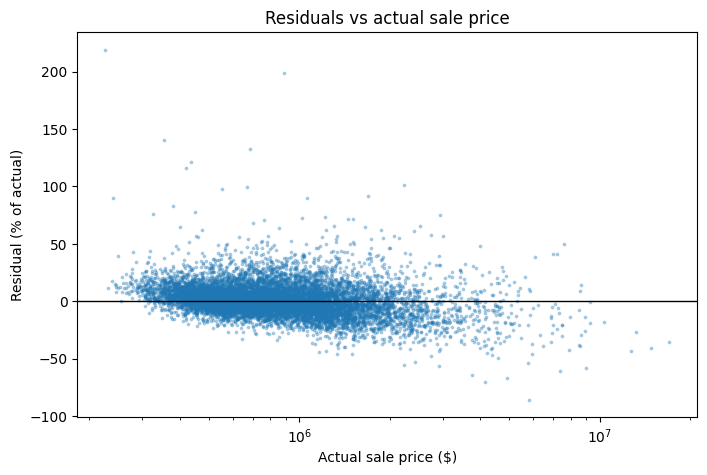

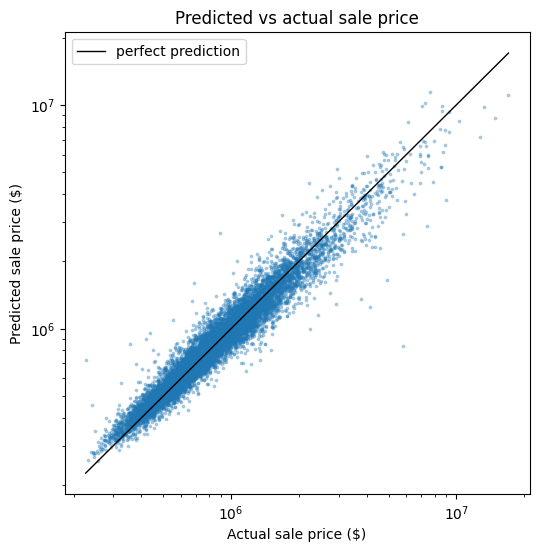

In [ ]:
import diagnostics

diagnostics.plot_residuals_vs_actual(actual, predicted)
diagnostics.plot_predicted_vs_actual(actual, predicted)



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_residuals_by_feature(X, actual, predicted, max_categories=20, n_cols=3):
    """One panel per column of X: a scatter plot for continuous columns and a box plot
    for categorical ones. Numeric columns with at most max_categories distinct values
    (bedrooms, month, ...) count as categorical. Columns with more categories than that
    show only their max_categories most common values."""
    residual = percent_error(actual, predicted)
    n_rows = int(np.ceil(len(X.columns) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows), squeeze=False)

    for ax, column in zip(axes.flat, X.columns):
        values = X[column].to_numpy()
        is_numeric = pd.api.types.is_numeric_dtype(X[column])
        if is_numeric and X[column].nunique() > max_categories:
            ax.scatter(values, residual, s=3, alpha=0.3)
        else:
            if is_numeric:
                order = sorted(X[column].value_counts().index[:max_categories])
            else:
                order = (
                    pd.DataFrame({"category": X[column], "residual": residual})
                    .groupby("category")["residual"]
                    .mean()
                    .sort_values(ascending=False)
                    .head(max_categories)
                    .index
                    .tolist()
                )
            sns.boxplot(x=values, y=residual, order=order, showfliers=False, ax=ax)
            ax.tick_params(axis="x", rotation=90)
        ax.axhline(0, color="black", linewidth=1)
        ax.set(title=column, xlabel="", ylabel="Residual (%)")

    for ax in axes.flat[len(X.columns):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()

def percent_error(actual, predicted):
    return 100 * (np.asarray(predicted) / np.asarray(actual) - 1)

plot_residuals_by_feature(X_val, actual, predicted)

In [ ]:
def evaluate_by_quantile(y_true, y_pred, n_bins=10):
    df = pd.DataFrame({
        "actual": y_true,
        "predicted": y_pred
    })
    df["quantile"] = pd.qcut(
        df["actual"], q=n_bins, duplicates="drop"
    )
    df["residual"] = df["actual"] - df["predicted"]
    df["residual_percent"] = 100 * np.abs(df["residual"]) / df["actual"]
    return df.groupby("quantile", observed=True).agg(
        count=("actual", "size"),
        MAE=("residual", lambda x: x.abs().mean()),
        mean_residual=("residual", "mean"),
        mean_residual_percent=("residual_percent", "mean"),
        mdape=("residual_percent", lambda x: np.median(np.abs(x))),
        mape=("residual_percent", lambda x: np.mean(np.abs(x)))
    )

evaluate_by_quantile(actual, predicted, n_bins=20)

,count,MAE,mean_residual,mean_residual_percent,mdape,mape
quantile,,,,,,
"(226199.999, 388140.0]",504,39370.109127,-35755.736111,11.831058,9.566599,11.831058
"(388140.0, 440480.0]",503,37608.620278,-28656.023857,9.022509,6.709461,9.022509
"(440480.0, 482100.0]",505,36901.689109,-23070.964356,7.978495,6.054259,7.978495
"(482100.0, 521000.0]",503,36429.673956,-17300.783300,7.246153,5.908113,7.246153
"(521000.0, 558000.0]",503,43382.990060,-20164.103380,8.031694,5.991995,8.031694
"(558000.0, 597040.0]",503,47213.089463,-16083.244533,8.169602,6.209370,8.169602
"(597040.0, 643360.0]",503,48521.813121,-16481.697813,7.818911,5.900389,7.818911
"(643360.0, 692020.0]",504,62446.601190,-22416.803571,9.365788,6.478539,9.365788
"(692020.0, 747620.0]",503,70470.473161,-21206.178926,9.795048,7.563032,9.795048
